# 前景价值（TK）

**行为金融因子 —— 投资者前景理论偏好**

① 以个股过去 $N$ 日收益率序列作为未来收益分布的预测。将负收益率从小到大排列为 $r_{-m}, \dots, r_{-1}$，正收益率从小到大排列为 $r_1, \dots, r_n$，加上零收益 $r_0$，每个收益出现的概率均为 $1/N$，其中 $N = m + n + 1$：

$$
\left( r_{-m}, \frac{1}{N}; \dots; r_{-1}, \frac{1}{N}; r_0, \frac{1}{N}; r_1, \frac{1}{N}; \dots; r_n, \frac{1}{N} \right)
$$

② 利用价值函数和概率权重函数计算前景价值 TK：

$$
\text{TK} = \sum_{i=-m}^{-1} v(r_i) \left[ w\left(\frac{-i+m+1}{N}\right) - w\left(\frac{-i+m}{N}\right) \right] + \sum_{i=1}^{n} v(r_i) \left[ w\left(\frac{n-i+1}{N}\right) - w\left(\frac{n-i}{N}\right) \right]
$$

更紧凑地，前景价值可表达为：

$$
\text{TK} = \sum_{i=-m}^{n} v(r_i) \cdot \pi_i
$$

其中 $\pi_i$ 为对应于收益率 $r_i$ 的概率权重。

③ 价值函数 $v(x)$ 和概率权重函数 $w^+(P)$、$w^-(P)$ 如下所示，函数参数取值为 $\alpha = 0.88$，$\lambda = 2.25$，$\gamma = 0.61$，$\delta = 0.69$：

$$
v(x) =\begin{cases}x^{\alpha}, & x \geq 0 \\-\lambda (-x)^{\alpha}, & x < 0\end{cases}
$$$$
w^+(P) = \frac{P^{\gamma}}{\left( P^{\gamma} + (1-P)^{\gamma} \right)^{1/\gamma}}
$$$$
w^-(P) = \frac{P^{\delta}}{\left( P^{\delta} + (1-P)^{\delta} \right)^{1/\delta}}
$$

其中，$w^+(P)$ 用于盈利概率的权重处理，$w^-(P)$ 用于亏损概率的权重处理。

## 因子说明

前景价值（TK）代表了投资者对每只个股的“综合打分”，其理论基础源于行为金融学中的**前景理论**（Prospect Theory）。根据前景理论，投资者在决策时并非基于客观的期望效用，而是基于对收益和损失的主观价值评估，同时对小概率事件存在过度权重、对大概率事件存在权重不足的倾向。TK 因子通过将个股的历史收益率分布代入价值函数和权重函数，量化了投资者对该股票的主观偏好程度。由于价值量 TK 高的股票在投资者眼中更具吸引力，投资者倾向于买入那些 TK 值较高的股票，导致这些股票被过度追捧、价格被高估；而 TK 值较低的股票则因缺乏关注而被低估。因此，股票的未来预期收益率与当前的前景价值 TK 呈**负相关**关系，TK 越高，未来收益越低；TK 越低，未来收益越高。

数据：日度收盘价

In [1]:
import numpy as np
import pandas as pd

from rqdatac import (
    all_instruments,
    get_price,
    get_trading_dates,
)


def _tk_probability_weight(probability, parameter):
    """Tversky-Kahneman 概率权重函数。"""
    probability = np.asarray(probability, dtype=float)

    numerator = np.power(probability, parameter)
    denominator = np.power(
        np.power(probability, parameter)
        + np.power(1.0 - probability, parameter),
        1.0 / parameter,
    )

    return numerator / denominator


def _tk_value_from_return_window(
    return_window,
    alpha=0.88,
    loss_aversion=2.25,
    gamma=0.61,
    delta=0.69,
):
    """
    对一个“历史收益窗口 × 股票”的 ndarray 计算 TK。
    每一列是一只股票的过去 N 日收益率。
    """
    n_obs, n_stocks = return_window.shape
    result = np.full(n_stocks, np.nan)

    # 只有窗口内每天都有有效交易收益率的股票才计算
    valid = np.isfinite(return_window).all(axis=0)
    if not valid.any():
        return result

    values = return_window[:, valid]

    loss_count = (values < 0).sum(axis=0)
    gain_count = (values > 0).sum(axis=0)

    # 将损失、盈利收益分别由小到大排序。
    # np.inf 会排在最后，因此前 loss_count / gain_count 个即为有效值。
    loss_sorted = np.sort(
        np.where(values < 0, values, np.inf),
        axis=0,
    )
    gain_sorted = np.sort(
        np.where(values > 0, values, np.inf),
        axis=0,
    )

    tk_valid = np.zeros(values.shape[1])

    # 损失侧：
    # pi_i^- = w^-((i+m+1)/N) - w^-((i+m)/N)
    for count in np.unique(loss_count):
        if count == 0:
            continue

        columns = np.flatnonzero(loss_count == count)
        loss_values = loss_sorted[:count, columns]

        probabilities = np.arange(1, count + 1, dtype=float) / n_obs
        previous_probabilities = np.arange(0, count, dtype=float) / n_obs

        weights = (
            _tk_probability_weight(probabilities, delta)
            - _tk_probability_weight(previous_probabilities, delta)
        )

        loss_utility = -loss_aversion * np.power(
            -loss_values,
            alpha,
        )

        tk_valid[columns] += (
            loss_utility * weights[:, None]
        ).sum(axis=0)

    # 盈利侧：
    # pi_i^+ = w^+((n-i+1)/N) - w^+((n-i)/N)
    for count in np.unique(gain_count):
        if count == 0:
            continue

        columns = np.flatnonzero(gain_count == count)
        gain_values = gain_sorted[:count, columns]

        probabilities = (
            np.arange(count, 0, -1, dtype=float) / n_obs
        )
        previous_probabilities = (
            np.arange(count - 1, -1, -1, dtype=float) / n_obs
        )

        weights = (
            _tk_probability_weight(probabilities, gamma)
            - _tk_probability_weight(previous_probabilities, gamma)
        )

        gain_utility = np.power(gain_values, alpha)

        tk_valid[columns] += (
            gain_utility * weights[:, None]
        ).sum(axis=0)

    result[valid] = tk_valid
    return result


def _tk_get_close_volume(batch, price_dates):
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )


def calculate_tk_daily(
    start_date,
    end_date,
    window=60,
    candidate_ids=None,
    alpha=0.88,
    loss_aversion=2.25,
    gamma=0.61,
    delta=0.69,
    batch_size=500,
):
    """
    前景价值因子（TK）

    输出：
        index  : [date, order_book_id]
        column : TK

    注意：
        window=60 表示使用过去 60 个交易日收益率；
        因子在当日收盘后完整可得，应于下一交易日使用。
    """
    if window < 2:
        raise ValueError("window 至少应为 2。")

    if candidate_ids is None:
        candidate_ids = (
            all_instruments("CS")["order_book_id"]
            .dropna()
            .drop_duplicates()
            .tolist()
        )
    else:
        candidate_ids = list(dict.fromkeys(candidate_ids))

    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(
                days=max((window + 1) * 3, 120)
            ),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < window:
        raise ValueError("历史交易日不足，无法计算 TK。")

    # 需要 window 个收益率，因此要额外多取一个价格日
    price_dates = calendar[first_loc - window:last_loc + 1]
    result_parts = []

    for start in range(0, len(candidate_ids), batch_size):
        batch = candidate_ids[start:start + batch_size]

        close, volume = _tk_get_close_volume(
            batch=batch,
            price_dates=price_dates,
        )

        if close is None:
            continue

        stock_return = close.pct_change(fill_method=None).iloc[1:]

        # 停牌日不将“价格不变”误视为零收益
        stock_return = stock_return.where(volume.iloc[1:].gt(0))

        return_values = stock_return.values.astype(float)
        target_locs = stock_return.index.get_indexer(target_dates)

        tk_wide = pd.DataFrame(
            index=target_dates,
            columns=batch,
            dtype=float,
        )

        for output_loc, return_loc in enumerate(target_locs):
            history_returns = return_values[
                return_loc - window + 1:return_loc + 1,
                :
            ]

            tk_wide.iloc[output_loc] = _tk_value_from_return_window(
                return_window=history_returns,
                alpha=alpha,
                loss_aversion=loss_aversion,
                gamma=gamma,
                delta=delta,
            )

        part = tk_wide.stack(dropna=True).rename("TK").to_frame()
        result_parts.append(part)

    if not result_parts:
        empty_index = pd.MultiIndex.from_arrays(
            [[], []],
            names=["date", "order_book_id"],
        )
        return pd.DataFrame(index=empty_index, columns=["TK"])

    result = pd.concat(result_parts).sort_index()
    result.index = result.index.set_names(["date", "order_book_id"])

    return result

In [2]:
tk = calculate_tk_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    window=60,
    candidate_ids=None,  # 全 A 股
    batch_size=500,
)

tk.head()

TK
date       order_book_id          
2020-01-02 000001.XSHE   -0.012430
           000002.XSHE   -0.002185
           000005.XSHE   -0.016968
           000006.XSHE   -0.009527
           000007.XSHE   -0.008930

In [3]:
tk_df = (
    tk["TK"]
    .unstack("order_book_id")
    .sort_index()
)

tk_df.index = pd.to_datetime(tk_df.index)
tk_df.columns.name = "order_book_id"

tk_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,688787.XSHG,688788.XSHG,688789.XSHG,688793.XSHG,688798.XSHG,688799.XSHG,688800.XSHG,688819.XSHG,688981.XSHG,689009.XSHG
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,-0.012430,-0.002185,NaN,-0.016968,-0.009527,-0.008930,-0.009861,0.001536,-0.009232,-0.014835,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,-0.012108,-0.002670,NaN,-0.017054,-0.009190,-0.010130,-0.009927,-0.001107,-0.009232,-0.014884,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,-0.013155,-0.003616,NaN,-0.017106,-0.009450,-0.012071,-0.010296,0.001030,-0.008998,-0.015235,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,-0.013499,-0.003666,NaN,-0.017050,-0.009578,-0.011576,-0.010378,0.000951,-0.008337,-0.015138,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,-0.014839,-0.003201,NaN,-0.018109,-0.010543,-0.012316,-0.011308,0.000612,-0.008841,-0.017153,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,-0.005650,-0.026896,-0.026295,NaN,-0.025883,-0.004157,-0.010590,-0.026793,-0.029564,-0.021004,...,-0.027510,-0.020777,-0.018555,-0.022045,-0.026270,-0.031850,-0.025285,-0.014581,-0.027223,-0.023807
2025-12-26,-0.005500,-0.026831,-0.025809,NaN,-0.025744,-0.004422,-0.010145,-0.030125,-0.029510,-0.020749,...,-0.027230,-0.023856,-0.018788,-0.038100,-0.026687,-0.031867,-0.026069,-0.014199,-0.027280,-0.025628
2025-12-29,-0.005468,-0.027116,-0.025859,NaN,-0.027579,-0.004624,-0.011073,-0.029424,-0.028860,-0.021308,...,-0.024382,-0.022705,-0.018986,-0.038200,-0.025789,-0.031901,-0.022121,-0.014956,-0.026678,-0.025546


In [4]:
from rqfactor.notebook import factor_analysis

result_tk = factor_analysis(
    f=tk_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_tk.show()

Loading BokehJS ...

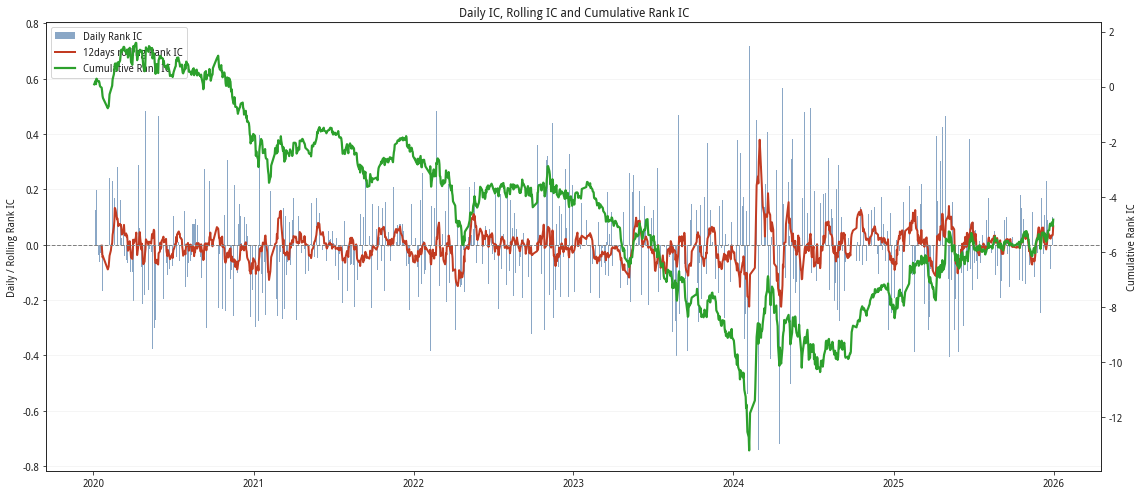

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_tk.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()

# 基于 PB 的前景价值 TK

**行为金融因子 —— 前景理论**

① 以个股过去 $N$ 期的估值变化率（PB 估值变化率）作为衡量公司价值的代理变量，构建未来价值变化率的概率分布。将负变化率从小到大排列为 $r_{pb,-m}, \dots, r_{pb,-1}$，正变化率从小到大排列为 $r_{pb,1}, \dots, r_{pb,n}$，加上零变化率 $r_{pb,0}$，每个变化率出现的概率均为 $1/N$，其中 $N = m + n + 1$：

$$
\left( r_{pb,-m}, \frac{1}{N}; \dots; r_{pb,-1}, \frac{1}{N}; r_{pb,0}, \frac{1}{N}; r_{pb,1}, \frac{1}{N}; \dots; r_{pb,n}, \frac{1}{N} \right)
$$

② 利用价值函数和概率权重函数计算前景价值 TK：

$$
\text{TK} = \sum_{i=-m}^{-1} v(r_{pb,i}) \left[ w^-\left(\frac{i+m+1}{N}\right) - w^-\left(\frac{i+m}{N}\right) \right] + \sum_{i=1}^{n} v(r_{pb,i}) \left[ w^+\left(\frac{n-i+1}{N}\right) - w^+\left(\frac{n-i}{N}\right) \right]
$$

③ 价值函数 $v(x)$ 和概率权重函数 $w^+(P)$、$w^-(P)$ 的参数取值与标准前景理论一致，取值为 $\alpha = 0.88$，$\lambda = 2.25$，$\gamma = 0.61$，$\delta = 0.69$：

$$
v(x) =\begin{cases}x^{\alpha}, & x \geq 0 \\-\lambda (-x)^{\alpha}, & x < 0\end{cases}
$$$$
w^+(P) = \frac{P^{\gamma}}{\left( P^{\gamma} + (1-P)^{\gamma} \right)^{1/\gamma}}
$$$$
w^-(P) = \frac{P^{\delta}}{\left( P^{\delta} + (1-P)^{\delta} \right)^{1/\delta}}
$$

其中，$w^+(P)$ 用于估值上升（盈利）概率的权重处理，$w^-(P)$ 用于估值下降（亏损）概率的权重处理。

## 因子说明

前景价值 TK 代表了投资者对每只个股估值水平的“综合打分”。与标准 TK 因子以历史收益率作为价值参考不同，**基于 PB 的前景价值 TK 采用 PB 估值变化率作为衡量公司价值的代理变量**。

其核心逻辑在于：投资者在决策时，会基于公司估值的历史变化形成参考点，高估值股票虽然当前价值量（TK）较高，但投资者倾向于认为其估值过高而选择卖出，导致卖出压力增大、股价被低估；相反，低估值股票因具备安全边际而受到投资者青睐，导致买入需求增加、股价被高估。

因此，在该框架下，**前景价值 TK 与股票未来预期收益呈正相关关系**：TK 值越高（对应高估值股票），未来收益反而可能更高（因超卖后的价格修复）；TK 值越低（对应低估值股票），未来收益反而可能更低（因超买后的价格回落）。

数据：PB估值

In [6]:
import numpy as np
import pandas as pd

from rqdatac import (
    all_instruments,
    get_factor,
    get_trading_dates,
)


def _pb_tk_probability_weight(probability, parameter):
    """前景理论概率权重函数。"""
    probability = np.asarray(probability, dtype=float)

    numerator = np.power(probability, parameter)
    denominator = np.power(
        np.power(probability, parameter)
        + np.power(1.0 - probability, parameter),
        1.0 / parameter,
    )

    return numerator / denominator


def _pb_tk_value_from_window(
    value_changes,
    alpha=0.88,
    loss_aversion=2.25,
    gamma=0.61,
    delta=0.69,
):
    """
    对一个“过去 N 期 PB 变化率 × 股票”的数组计算 TK。
    每列对应一只股票。
    """
    n_obs, n_stocks = value_changes.shape
    result = np.full(n_stocks, np.nan)

    valid = np.isfinite(value_changes).all(axis=0)
    if not valid.any():
        return result

    values = value_changes[:, valid]

    loss_count = (values < 0).sum(axis=0)
    gain_count = (values > 0).sum(axis=0)

    # 损失、盈利变化率分别从小到大排序
    loss_sorted = np.sort(
        np.where(values < 0, values, np.inf),
        axis=0,
    )
    gain_sorted = np.sort(
        np.where(values > 0, values, np.inf),
        axis=0,
    )

    tk_value = np.zeros(values.shape[1])

    # 损失侧概率权重
    for count in np.unique(loss_count):
        if count == 0:
            continue

        columns = np.flatnonzero(loss_count == count)
        loss_values = loss_sorted[:count, columns]

        probability = (
            np.arange(1, count + 1, dtype=float) / n_obs
        )
        previous_probability = (
            np.arange(0, count, dtype=float) / n_obs
        )

        weights = (
            _pb_tk_probability_weight(probability, delta)
            - _pb_tk_probability_weight(
                previous_probability,
                delta,
            )
        )

        utility = -loss_aversion * np.power(
            -loss_values,
            alpha,
        )

        tk_value[columns] += (
            utility * weights[:, None]
        ).sum(axis=0)

    # 盈利侧概率权重
    for count in np.unique(gain_count):
        if count == 0:
            continue

        columns = np.flatnonzero(gain_count == count)
        gain_values = gain_sorted[:count, columns]

        probability = (
            np.arange(count, 0, -1, dtype=float) / n_obs
        )
        previous_probability = (
            np.arange(count - 1, -1, -1, dtype=float) / n_obs
        )

        weights = (
            _pb_tk_probability_weight(probability, gamma)
            - _pb_tk_probability_weight(
                previous_probability,
                gamma,
            )
        )

        utility = np.power(gain_values, alpha)

        tk_value[columns] += (
            utility * weights[:, None]
        ).sum(axis=0)

    result[valid] = tk_value

    return result


def _pb_tk_get_pb_wide(
    order_book_ids,
    dates,
    pb_field="pb_ratio_lf",
    batch_size=500,
):
    """下载 PB 因子并整理为 日期 × 股票 宽表。"""
    parts = []

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        raw = get_factor(
            order_book_ids=batch,
            factor=pb_field,
            start_date=dates[0],
            end_date=dates[-1],
            expect_df=True,
        )

        if raw is None or raw.empty:
            continue

        if isinstance(raw.index, pd.MultiIndex):
            pb_wide = raw[pb_field].unstack("order_book_id")
        else:
            pb_wide = raw[[pb_field]].rename(
                columns={pb_field: batch[0]}
            )

        pb_wide.index = pd.to_datetime(pb_wide.index)

        parts.append(
            pb_wide.reindex(index=dates, columns=batch)
        )

    if not parts:
        raise RuntimeError("未取得有效 PB 因子数据。")

    result = pd.concat(parts, axis=1)
    result = result.loc[:, ~result.columns.duplicated()]

    return result.reindex(
        index=dates,
        columns=order_book_ids,
    )


def calculate_pb_tk_daily(
    start_date,
    end_date,
    window=60,
    candidate_ids=None,
    pb_field="pb_ratio_lf",
    alpha=0.88,
    loss_aversion=2.25,
    gamma=0.61,
    delta=0.69,
    batch_size=500,
):
    """
    基于 PB 估值变化率的前景价值（TK）

    估值变化率：
        r_pb,t = PB_t / PB_(t-1) - 1

    输出：
        index  : [date, order_book_id]
        column : TK_PB

    window=60：
        使用过去 60 个交易日的 PB 估值变化率构造前景价值。
    """
    if window < 2:
        raise ValueError("window 至少应为 2。")

    if candidate_ids is None:
        candidate_ids = (
            all_instruments("CS")["order_book_id"]
            .dropna()
            .drop_duplicates()
            .tolist()
        )
    elif isinstance(candidate_ids, str):
        candidate_ids = [candidate_ids]
    else:
        candidate_ids = list(dict.fromkeys(candidate_ids))

    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(
                days=max((window + 1) * 3, 120)
            ),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < window:
        raise ValueError("历史交易日不足，无法计算 TK_PB。")

    # 计算 window 个 PB 变化率，需要额外一日 PB 水平值
    pb_dates = calendar[
        first_loc - window:last_loc + 1
    ]

    pb_wide = _pb_tk_get_pb_wide(
        order_book_ids=candidate_ids,
        dates=pb_dates,
        pb_field=pb_field,
        batch_size=batch_size,
    )

    # 非正 PB 通常对应负净资产或异常估值，不纳入前景价值分布
    pb_wide = pb_wide.where(pb_wide > 0)

    pb_change = pb_wide.pct_change(fill_method=None).iloc[1:]

    pb_change_values = pb_change.values.astype(float)
    target_locs = pb_change.index.get_indexer(target_dates)

    factor_wide = pd.DataFrame(
        index=target_dates,
        columns=candidate_ids,
        dtype=float,
    )

    for output_loc, change_loc in enumerate(target_locs):
        history_changes = pb_change_values[
            change_loc - window + 1:change_loc + 1,
            :
        ]

        factor_wide.iloc[output_loc] = _pb_tk_value_from_window(
            value_changes=history_changes,
            alpha=alpha,
            loss_aversion=loss_aversion,
            gamma=gamma,
            delta=delta,
        )

    result = (
        factor_wide
        .stack(dropna=True)
        .rename("TK_PB")
        .to_frame()
    )
    result.index = result.index.set_names(
        ["date", "order_book_id"]
    )

    return result

In [7]:
tk_pb = calculate_pb_tk_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    window=60,
    candidate_ids=None,
    pb_field="pb_ratio_lf",
    batch_size=500,
)

tk_pb.head()

# TK_PB 越高，表示近期 PB 估值变化分布在前景理论下越具吸引力；越低则代表近期估值下行及其损失厌恶效应更突出。代码仍按标准 TK 处理：使用过去 window 个实际 PB 变化率，实际出现的零变化率自然保留，但不额外插入人为零值。因子在 t 日收盘后完整可得，建议用于 t+1 日交易。

TK_PB
date       order_book_id          
2020-01-02 000001.XSHE   -0.027897
           000002.XSHE   -0.004396
           000004.XSHE   -0.008058
           000005.XSHE   -0.015810
           000006.XSHE   -0.011180

In [9]:
tk_pb_df = (
    tk_pb["TK_PB"]
    .unstack("order_book_id")
    .sort_index()
)

tk_pb_df.index = pd.to_datetime(tk_pb_df.index)
tk_pb_df.columns.name = "order_book_id"

tk_pb_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,603406.XSHG,301632.XSHE,603370.XSHG,301575.XSHE,603418.XSHG,301584.XSHE,301656.XSHE,301668.XSHE,001285.XSHE,301563.XSHE
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,-0.027897,-0.004396,-0.008058,-0.015810,-0.011180,-0.008331,-0.009684,0.001413,-0.011144,-0.014737,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,-0.027575,-0.004851,-0.008204,-0.015896,-0.010835,-0.009512,-0.009748,-0.001230,-0.011144,-0.014785,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,-0.028622,-0.005762,-0.009204,-0.015948,-0.011095,-0.011431,-0.010117,0.000909,-0.010911,-0.015137,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,-0.028966,-0.005814,-0.009116,-0.015892,-0.011228,-0.010939,-0.010192,0.000830,-0.010249,-0.015040,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,-0.030297,-0.005361,-0.009248,-0.016952,-0.012145,-0.011668,-0.011122,0.000491,-0.010751,-0.017055,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,-0.008562,-0.023548,-0.076059,NaN,-0.026368,-0.004159,-0.010583,-0.026859,-0.032569,-0.021214,...,-0.044873,-0.048509,-0.070537,-0.069521,-0.085776,NaN,NaN,NaN,NaN,NaN
2025-12-26,-0.008413,-0.023483,-0.075573,NaN,-0.026229,-0.004424,-0.010138,-0.030197,-0.032517,-0.020959,...,-0.047284,-0.048332,-0.070821,-0.070161,-0.083625,-0.067827,-0.076836,NaN,NaN,NaN
2025-12-29,-0.008382,-0.023768,-0.075623,NaN,-0.028049,-0.004626,-0.011066,-0.029496,-0.031867,-0.021519,...,-0.047747,-0.047119,-0.070345,-0.069823,-0.082664,-0.057413,-0.077472,-0.097651,NaN,NaN


In [10]:
from rqfactor.notebook import factor_analysis

result_tk_pb = factor_analysis(
    f=tk_pb_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_tk_pb.show()

Loading BokehJS ...

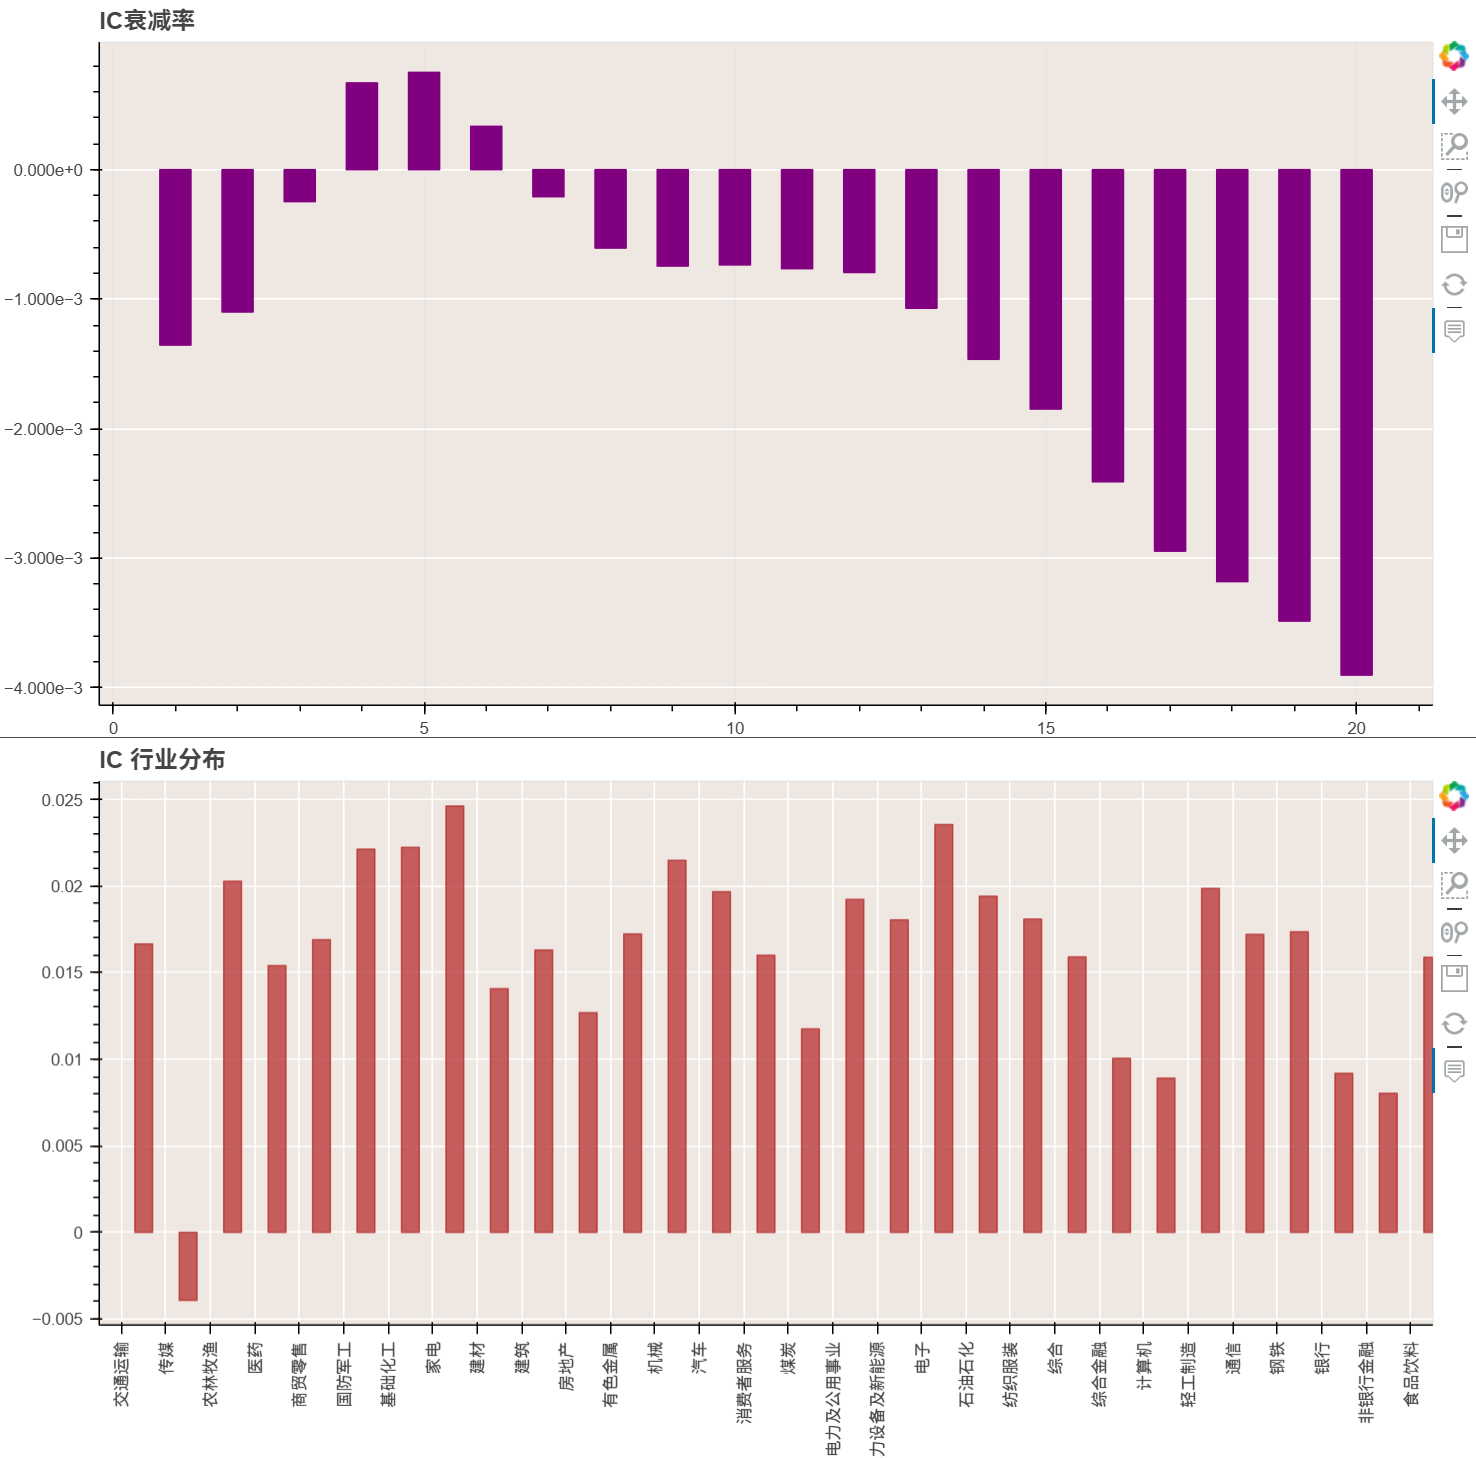

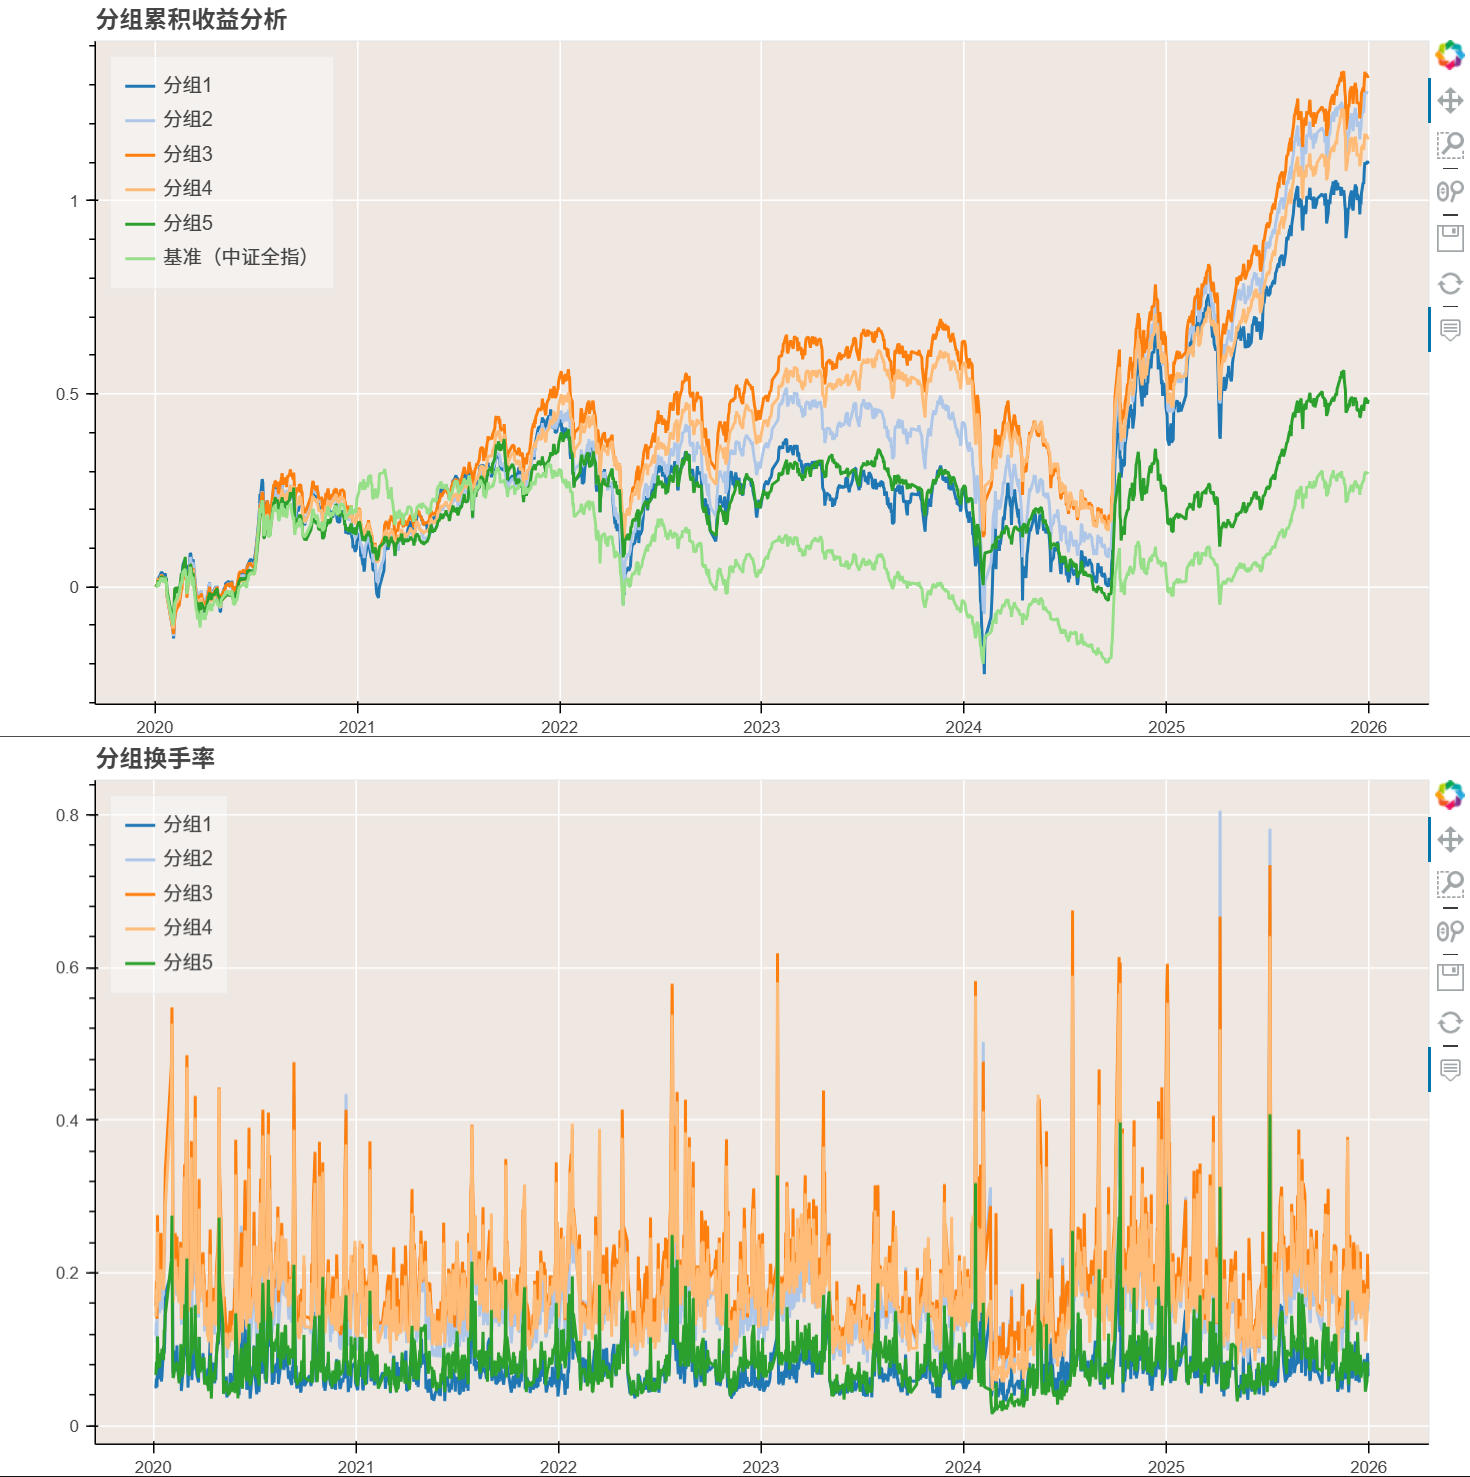

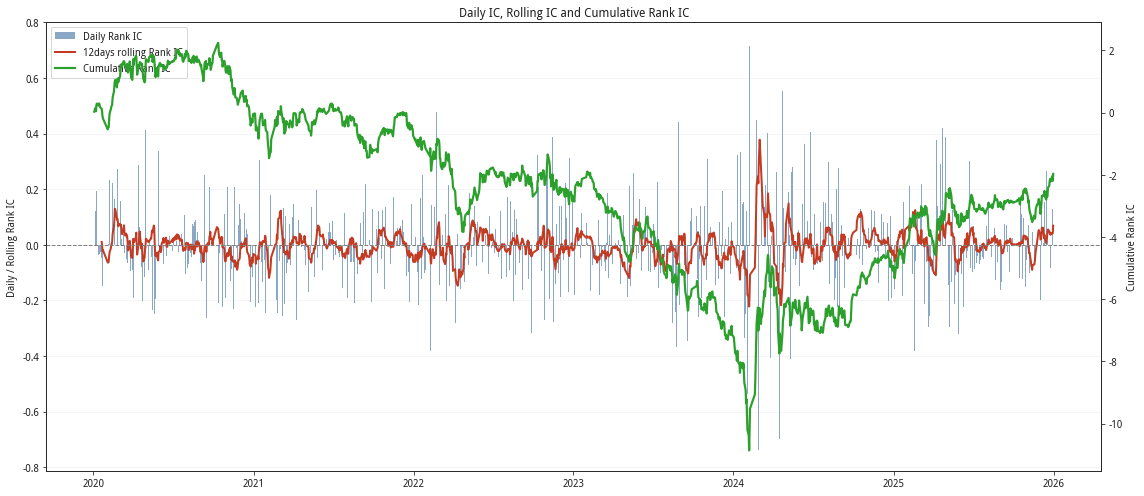

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_tk_pb.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()